<a href="https://colab.research.google.com/github/jovanfranco/usdmxn-volatilidad/blob/main/clase5_cruce_promedios.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import yfinance as yf
import matplotlib.pyplot as plt

datos = yf.download("MXN=X", start="2020-01-01", progress=False)
cierre = datos["Close"].squeeze()
rend = cierre.pct_change().dropna()

/tmp/ipykernel_5930/1200959363.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  datos = yf.download("MXN=X", start="2020-01-01", progress=False)


In [2]:
rapida = cierre.rolling(20).mean()
lenta = cierre.rolling(100).mean()
senal = (rapida > lenta).astype(int) * 2 - 1

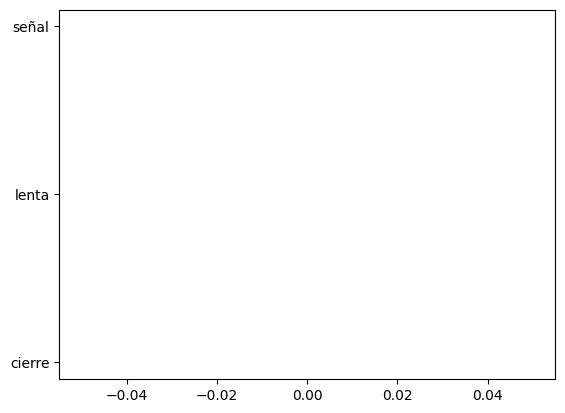

In [3]:
plt.plot ("cierre")
plt.plot  ("lenta")
plt.plot ("señal")

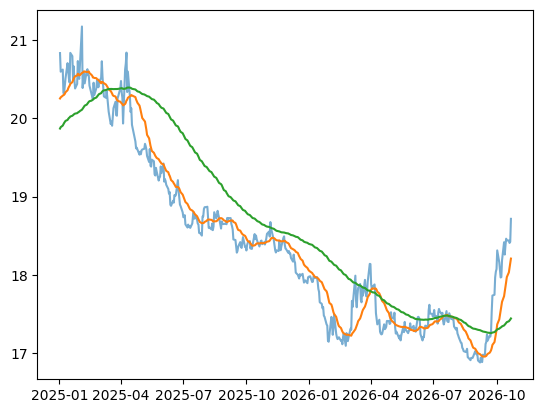

In [4]:
plt.plot(cierre["2025-01-01":], label="USD/MXN", alpha=0.6)
plt.plot(rapida["2025-01-01":], label="Promedio 20 días")
plt.plot(lenta["2025-01-01":], label="Promedio 100 días")

In [5]:
posicion = senal.shift(1)
rend_est = (posicion * rend).dropna()

In [6]:
costo_por_unidad = 0.0001
cambios = posicion.diff().abs().reindex(rend_est.index)
rend_neto = rend_est - cambios * costo_por_unidad

In [7]:
def metricas(r):
    ret = float(r.mean() * 252)
    vol = float(r.std() * 252 ** 0.5)
    curva = (1 + r).cumprod()
    caida = float((curva / curva.cummax() - 1).min())
    return round(ret, 3), round(vol, 3), round(ret / vol, 2), round(caida, 3)

comparar = rend.loc[rend_neto.index]
print("Comprar y mantener | Rend, Vol, Sharpe, Caida maxima:", metricas(comparar))
print("Cruce 20/100 neto  | Rend, Vol, Sharpe, Caida maxima:", metricas(rend_neto))
print("Cambios de posicion:", int((cambios > 0).sum()))

Comprar y mantener | Rend, Vol, Sharpe, Caida maxima: (0.006, 0.125, 0.05, -0.356)
Cruce 20/100 neto  | Rend, Vol, Sharpe, Caida maxima: (-0.032, 0.125, -0.25, -0.388)
Cambios de posicion: 23


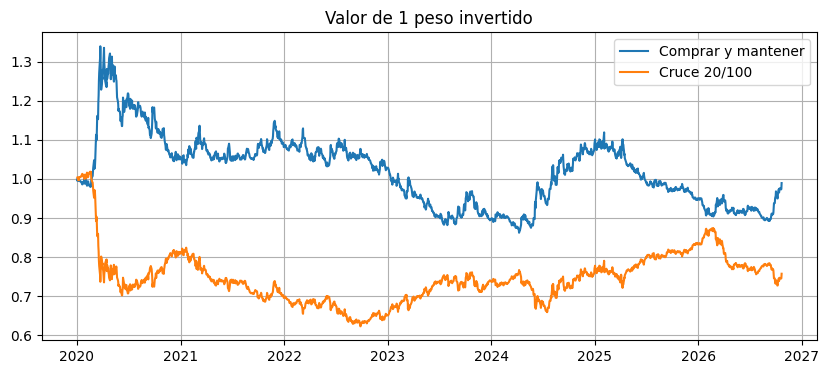

In [8]:
plt.figure(figsize=(10, 4))
plt.plot((1 + comparar).cumprod(), label="Comprar y mantener")
plt.plot((1 + rend_neto).cumprod(), label="Cruce 20/100")
plt.title("Valor de 1 peso invertido")
plt.legend()
plt.grid(True)
plt.show()

In [9]:
rapida = cierre.rolling(10).mean()
lenta = cierre.rolling(50).mean()
senal = (rapida > lenta).astype(int) * 2 - 1

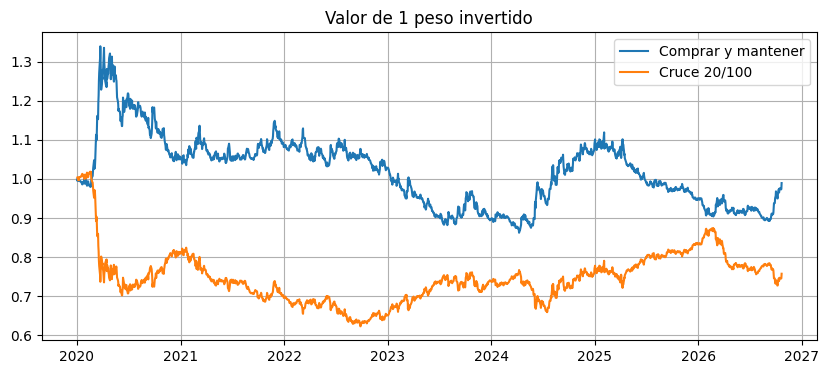

In [10]:
plt.figure(figsize=(10, 4))
plt.plot((1 + comparar).cumprod(), label="Comprar y mantener")
plt.plot((1 + rend_neto).cumprod(), label="Cruce 20/100")
plt.title("Valor de 1 peso invertido")
plt.legend()
plt.grid(True)
plt.show()

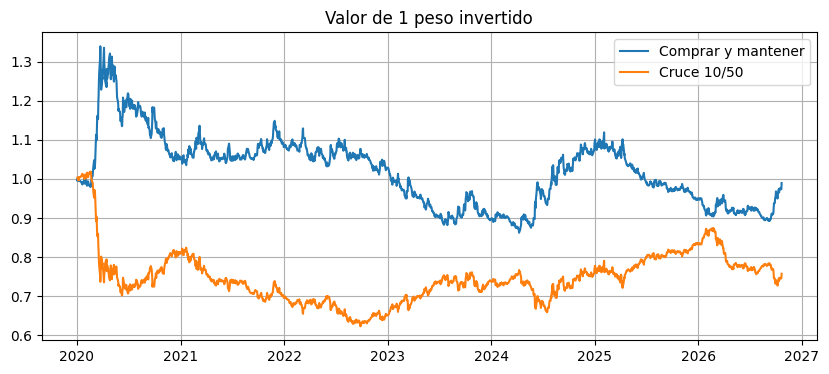

In [11]:
plt.figure(figsize=(10, 4))
plt.plot((1 + comparar).cumprod(), label="Comprar y mantener")
plt.plot((1 + rend_neto).cumprod(), label="Cruce 10/50")
plt.title("Valor de 1 peso invertido")
plt.legend()
plt.grid(True)
plt.show()

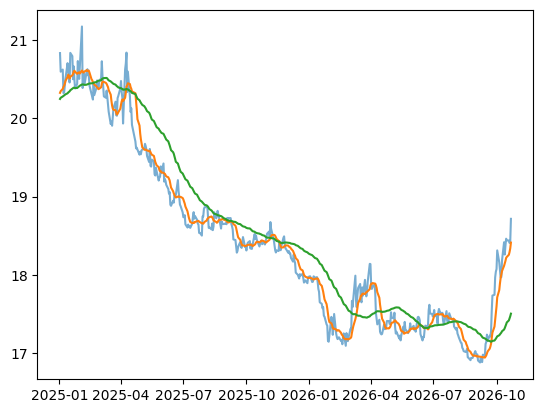

In [12]:
plt.plot(cierre["2025-01-01":], label="USD/MXN", alpha=0.6)
plt.plot(rapida["2025-01-01":], label="Promedio 10 días")
plt.plot(lenta["2025-01-01":], label="Promedio 50 días")

In [13]:
def probar(corta, larga, costo=0.0001):
    rap = cierre.rolling(corta).mean()
    len_ = cierre.rolling(larga).mean()
    sen = (rap > len_).astype(int) * 2 - 1
    pos = sen.shift(1)
    r_est = (pos * rend).dropna()
    camb = pos.diff().abs().reindex(r_est.index)
    r_neto = r_est - camb * costo
    return metricas(r_neto), int((camb > 0).sum())

for corta, larga in [(10, 50), (20, 100), (50, 200)]:
    m, n = probar(corta, larga)
    print(f"{corta}/{larga} | Rend, Vol, Sharpe, Caída: {m} | Cambios: {n}")

10/50 | Rend, Vol, Sharpe, Caída: (-0.032, 0.125, -0.26, -0.359) | Cambios: 61
20/100 | Rend, Vol, Sharpe, Caída: (-0.032, 0.125, -0.25, -0.388) | Cambios: 23
50/200 | Rend, Vol, Sharpe, Caída: (-0.015, 0.125, -0.12, -0.281) | Cambios: 9


In [1]:
import yfinance as yf
import matplotlib.pyplot as plt

# 1. Datos con fecha final fija, para que los números no cambien entre corridas
datos = yf.download("MXN=X", start="2020-01-01", end="2026-10-22", progress=False)
cierre = datos["Close"].squeeze()
rend = cierre.pct_change().dropna()

# 2. Métricas
def metricas(r):
    ret = float(r.mean() * 252)
    vol = float(r.std() * 252 ** 0.5)
    curva = (1 + r).cumprod()
    caida = float((curva / curva.cummax() - 1).min())
    return round(ret, 3), round(vol, 3), round(ret / vol, 2), round(caida, 3)

# 3. Estrategia: sin señal falsa mientras el promedio largo no existe
def estrategia(corta, larga, costo=0.0001):
    rap = cierre.rolling(corta).mean()
    lent = cierre.rolling(larga).mean()
    sen = (rap > lent).astype(int) * 2 - 1
    sen = sen.where(lent.notna())          # sin promedio largo, sin señal
    pos = sen.shift(1)                     # sin look ahead
    r_bruto = pos * rend
    camb = pos.diff().abs().fillna(0)
    r_neto = (r_bruto - camb * costo).dropna()
    return r_neto, int((camb > 0).sum())

# 4. Periodo común para que todas las combinaciones sean comparables
inicio = cierre.index[200]
combos = [(10, 50), (20, 100), (50, 200)]

print("Periodo:", inicio.date(), "a", cierre.index[-1].date())
print("Comprar y mantener:", metricas(rend.loc[inicio:]))

for corta, larga in combos:
    r, n = estrategia(corta, larga)
    r = r.loc[inicio:]
    mitad = len(r) // 2
    print(f"{corta}/{larga} | Rend, Vol, Sharpe, Caída: {metricas(r)} | Cambios: {n}"
          f" | Sharpe 1a mitad: {metricas(r.iloc[:mitad])[2]} | 2a mitad: {metricas(r.iloc[mitad:])[2]}")

/tmp/ipykernel_8313/768272397.py:5: FutureWarning: YF.download() has changed argument auto_adjust default to True
  datos = yf.download("MXN=X", start="2020-01-01", end="2026-10-22", progress=False)


Periodo: 2020-10-07 a 2026-10-21
Comprar y mantener: (-0.018, 0.108, -0.17, -0.249)
10/50 | Rend, Vol, Sharpe, Caída: (-0.044, 0.108, -0.41, -0.359) | Cambios: 60 | Sharpe 1a mitad: -0.55 | 2a mitad: -0.27
20/100 | Rend, Vol, Sharpe, Caída: (0.003, 0.108, 0.03, -0.244) | Cambios: 22 | Sharpe 1a mitad: 0.04 | 2a mitad: 0.01
50/200 | Rend, Vol, Sharpe, Caída: (0.003, 0.108, 0.03, -0.226) | Cambios: 8 | Sharpe 1a mitad: 0.09 | 2a mitad: -0.03
